In [86]:
import numpy as np
import pandas as pd

### Load DataSet

In [87]:
df = pd.read_excel('english_to_urdu_dataset.xlsx')
df = df.iloc[:10000]
df['urdu'] = df['urdu'].fillna('').astype(str).apply(lambda x: '<start>' + x + '<end>')
df.head()

,eng,urdu
0,the book of the generation of jesus christ th...,<start>یسوع مسیح ابن داود ابن ابرہام کا نسب نا...
1,abraham begat isaac and isaac begat jacob an...,<start>ابراہام سے اضحاق پیدا ہوا اور اضحاق سے ...
2,and judas begat phares and zara of thamar and...,<start>اور یہوداہ سے فارص اور زارح تمر سے پیدا...
3,and aram begat aminadab and aminadab begat na...,<start>اور رام سے عمینداب پیدا ہوا اور عمینداب...
4,and salmon begat booz of rachab and booz bega...,<start>اور سلمون سے بوعز راحب سے پیدا ہوا اور ...


### Train Test Split

In [88]:
english_sentence = df['eng'].values
urdu_sentence = df['urdu'].values

### Tokenization

In [89]:
from tensorflow.keras.preprocessing.text import Tokenizer

# English
eng_tokenizer = Tokenizer()
eng_tokenizer.fit_on_texts(english_sentence)
encoder_input = eng_tokenizer.texts_to_sequences(english_sentence)

# Urdu
urd_tokenizaer = Tokenizer(filters = '')
urd_tokenizaer.fit_on_texts(urdu_sentence)
decoder_input = urd_tokenizaer.texts_to_sequences(urdu_sentence)

### Add Padding

In [90]:
from tensorflow.keras.preprocessing.sequence import pad_sequences
encoder_input = pad_sequences(encoder_input, padding = 'post')
decoder_input = pad_sequences(decoder_input, padding = 'post')

### Vocabulary Size

In [91]:
eng_vocab_size = len(eng_tokenizer.word_index) + 1
urd_vocab_size = len(urd_tokenizaer.word_index) + 1

print("English : ", eng_vocab_size)
print("Urdu : ", urd_vocab_size)

English :  6561
Urdu :  8770


### Max Length

In [92]:
max_encoder = encoder_input.shape[1]
max_decoder = decoder_input.shape[1]

print("Max Encoder : ", max_encoder)
print("Max Decoder : ", max_decoder)

Max Encoder :  68
Max Decoder :  84


### Target

In [93]:
decoder_target = np.zeros_like(decoder_input)
decoder_target[:, : -1] = decoder_input[:, 1:]
decoder_target = np.expand_dims(decoder_target, -1)

## Model Archeticture

In [105]:
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import Input, Embedding, Attention, AdditiveAttention, concatenate, LSTM, Dense

### Encoder Archeticture

In [106]:
encoder_inputs = Input(shape = (max_encoder, ))
encoder_embedding = Embedding(input_dim = eng_vocab_size, output_dim = 100)(encoder_inputs)
encoder_outputs, state_h, state_c = LSTM(150, return_sequences=True, return_state=True)(encoder_embedding)


### Decoder Archeticture

In [107]:
decoder_inputs = Input(shape=(max_decoder, ))
decoder_embedding = Embedding(input_dim=urd_vocab_size, output_dim=100)(decoder_inputs)
decoder_outputs, _, _ = LSTM(150, return_sequences=True, return_state=True)(decoder_embedding)

# Output Layer == Note == This line will be added if you are using simply Encoder and Decoder
# decoder_outputs = Dense(urd_vocab_size, activation='softmax')(decoder_output)

### Single-Head Attention,  <=>  Bahdanau Attention,  <=>  Luong Attention Layer

In [108]:
# Single Head-Attention
# attention = Attention()
# attention_output = attention([decoder_outputs, encoder_outputs])


# Bahdanau Attention
# attention = AdditiveAttention()
# attention_output = attention([decoder_outputs, encoder_outputs])


# Luong Attention
attention = Attention()
attention_output = attention([decoder_outputs, encoder_outputs])

### Concatenate Attention + Decoder

In [ ]:
# Attention
cotext = concatenate([decoder_outputs, attention_output])
decoder_output = Dense(urd_vocab_size, activation='softmax')(cotext)

### Complete Model

In [110]:
model = Model(
    [encoder_inputs, decoder_inputs],
    decoder_output
)

## Model Compilation

In [111]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

### Model Traning

In [112]:
history = model.fit([encoder_input, decoder_input], decoder_target, batch_size=32, epochs=1, validation_split=0.2)

228/228 ━━━━━━━━━━━━━━━━━━━━ 537s 2s/step - accuracy: 0.7006 - loss: 3.3084 - val_accuracy: 0.8170 - val_loss: 1.2641


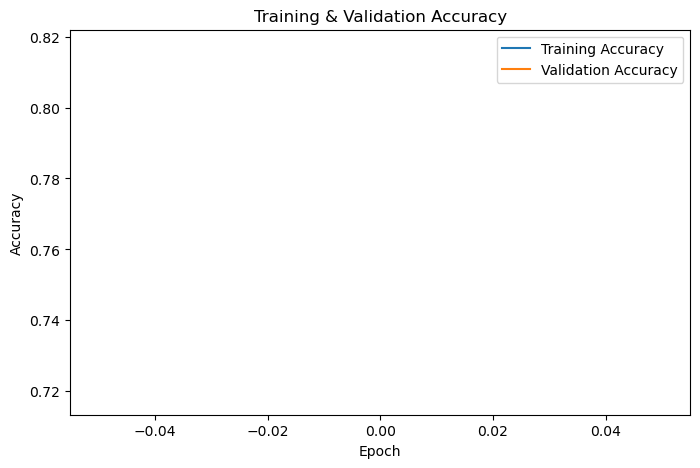

In [113]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training & Validation Accuracy")
plt.legend()
plt.show()

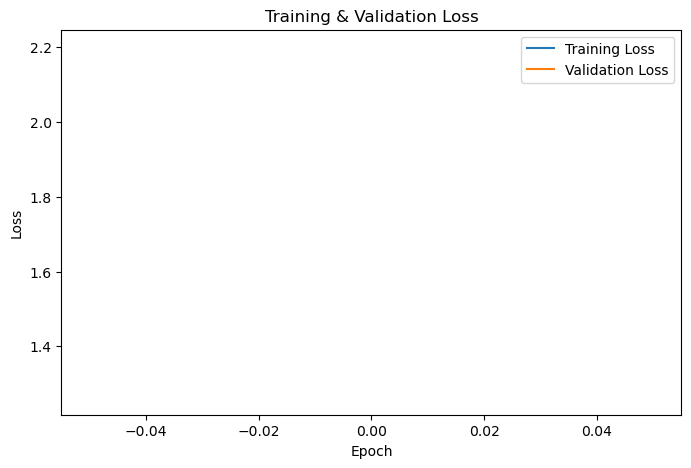

In [114]:
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training & Validation Loss")
plt.legend()
plt.show()